# Meta gene modules (MGMs) from ten ARCHS4 CLAMPfull models

Report of the CRISPR-Cas MGM analysis: technical noise screen of the LVs of the canonical model and nine seed replicates, clustering into MGMs (cosine >= 0.5, kept when present in >= 6 of 10 models), ORA, selection with the CRISPR lipid screen, PhenoPLIER traits and canonical pathways, sample projection, and the LINCS L1000 drugs of the four Figure 5 MGMs.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    I = snakemake.input
    FLAGS, SUMMARY, FUNNEL, PATHWAYS = Path(I.flags), Path(I.summary), Path(I.funnel), Path(I.pathways)
    MODULES, TRAITS, COMPOSITION, RANKING = Path(I.modules), Path(I.traits), Path(I.composition), Path(I.ranking)
    ORA = [Path(d) for d in I.ora]
except NameError:
    A4 = Path('../../../../output/03_model_biology/02_archs4')
    M = A4 / '04_crispercas/00_mgm'
    FLAGS, SUMMARY, FUNNEL, PATHWAYS = A4 / '06_technical_noise/seeds/all_flags.csv', M / 'cluster_summary.csv', M / 'selection/funnel.csv', M / 'pathways/canonical_bp_top.csv'
    MODULES, TRAITS, COMPOSITION, RANKING = M / 'fig5/modules.csv', M / 'fig5/module_trait_groups.csv', M / 'projection/composition.csv', M / 'l1000/l1000_fig5_ranking.csv'
    ORA = [M / 'ora' / d for d in ['bp', 'canonical', 'cellmarker', 'azimuth', 'archs4_cell_lines']]

def mgm(s):
    return s.str.replace('metaLV', 'MGM')

ORDER = ['MGM91', 'MGM588', 'MGM175', 'MGM335']
PICK = {'MGM91': 'Clomifene', 'MGM588': 'Clomifene', 'MGM175': 'Cortisone acetate', 'MGM335': 'Calcitriol'}

In [2]:
flags = pd.read_csv(FLAGS)
noise = flags.groupby('model', sort=False).agg(lvs=('LV', 'size'), gene_level=('gene_flag', 'sum'),
                                               sample_level=('sample_flag', 'sum'), removed=('any_flag', 'sum'))
noise['kept'] = noise.lvs - noise.removed
noise.loc['total'] = noise.sum()
display(noise)

,lvs,gene_level,sample_level,removed,kept
model,,,,,
S123,1728,91,39,116,1612
S1001,1728,86,58,136,1592
S1002,1728,92,58,139,1589
S1003,1728,86,70,146,1582
S1004,1728,90,48,129,1599
S1005,1728,86,49,127,1601
S1006,1728,88,53,134,1594
S1007,1728,82,72,143,1585
S456,1728,83,15,95,1633


15956 LVs -> 8025 clusters -> 618 MGMs present in >= 6/10 models


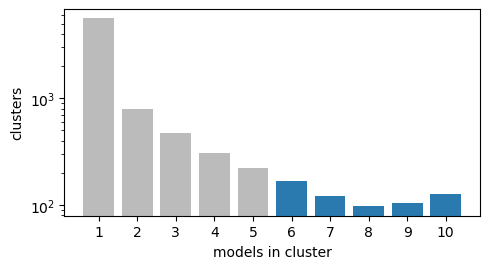

,count,mean,std,min,25%,50%,75%,max
n_lvs,618.0,8.01,1.65,6.0,7.00,8.00,9.00,20.00
n_models,618.0,7.84,1.50,6.0,6.00,8.00,9.00,10.00
min_cos,618.0,0.64,0.12,0.5,0.55,0.61,0.71,0.98
mean_cos,618.0,0.80,0.08,0.6,0.74,0.80,0.86,0.99


In [3]:
clusters = pd.read_csv(SUMMARY)
clusters['MGM'] = mgm(clusters.metaLV)
dist = pd.read_csv(SUMMARY.parent / 'cluster_model_count_distribution.csv', index_col=0)['count']
print(f"{noise.loc['total', 'kept']} LVs -> {dist.sum()} clusters -> {len(clusters)} MGMs present in >= 6/10 models")
fig, ax = plt.subplots(figsize=(5, 2.8))
ax.bar(dist.index, dist.values, color=['#BBBBBB' if n < 6 else '#2A7AB0' for n in dist.index])
ax.set(xlabel='models in cluster', ylabel='clusters', yscale='log', xticks=dist.index)
plt.tight_layout()
plt.show()
display(clusters[['n_lvs', 'n_models', 'min_cos', 'mean_cos']].describe().T.round(2))

In [4]:
ora = pd.concat([pd.read_csv(d / 'summary.csv') for d in ORA], ignore_index=True)
ora['MGMs_enriched'] = [pd.read_csv(d / 'enrichment.csv.gz', usecols=['LV', 'p.adjust']).query('`p.adjust` < 0.05').LV.nunique() for d in ORA]
display(ora.set_index('database_label')[['tested_lvs', 'eligible_pathways', 'recovered_pathways', 'recovered_percent', 'MGMs_enriched']].round(1))

,tested_lvs,eligible_pathways,recovered_pathways,recovered_percent,MGMs_enriched
database_label,,,,,
GO Biological Process,618,5879,5155,87.7,448
Canonical non-Reactome,618,1721,1651,95.9,435
CellMarker,618,289,284,98.3,388
Azimuth,618,1229,1177,95.8,430
ARCHS4 Cell-lines,618,125,125,100.0,609


In [5]:
funnel = pd.read_csv(FUNNEL)
STEPS = {'pass_gsea': 'CRISPR lipid screen genes enriched (GSEA FDR < 0.05)',
         'pass_trait': 'PhenoPLIER trait association (FDR < 0.05)',
         'pass_canonical': 'canonical pathway enriched (ORA FDR < 0.05)',
         'pass_screen_gene_top': 'screen gene in the top 185 loadings',
         'pass_missed_by_twas': 'screen gene not TWAS-associated with the trait (P >= 0.05)',
         'pass_lipid_pathway': 'lipid canonical pathway'}
steps = pd.Series({'clustered in >= 6/10 models': len(funnel)} | {v: int(funnel[k].sum()) for k, v in STEPS.items()}, name='MGMs')
display(steps.to_frame())
display(funnel[funnel.pass_gsea].assign(MGM=lambda d: mgm(d.metaLV)).sort_values('gsea_padj')
        [['MGM', 'n_models', 'gsea_padj', 'crispr_leading_edge'] + list(STEPS)[1:]].style.format({'gsea_padj': '{:.1e}'}).hide(axis='index'))

,MGMs
clustered in >= 6/10 models,618
CRISPR lipid screen genes enriched (GSEA FDR < 0.05),27
PhenoPLIER trait association (FDR < 0.05),19
canonical pathway enriched (ORA FDR < 0.05),13
screen gene in the top 185 loadings,13
screen gene not TWAS-associated with the trait (P >= 0.05),13
lipid canonical pathway,4


MGM,n_models,gsea_padj,crispr_leading_edge,pass_trait,pass_canonical,pass_screen_gene_top,pass_missed_by_twas,pass_lipid_pathway
MGM101,10,1.5e-04,HILPDA,False,False,False,False,False
MGM278,8,7.6e-04,DGAT2,True,True,True,True,False
MGM474,6,9.4e-04,DGAT2,False,False,False,False,False
MGM499,6,1.5e-03,"SOX9, HILPDA",True,False,False,False,False
MGM91,10,1.7e-03,ACACA,True,True,True,True,True
MGM380,7,1.9e-03,PTEN,True,False,False,False,False
MGM209,9,1.9e-03,DGAT2,True,True,True,True,False
MGM298,8,1.9e-03,SOX9,True,True,True,True,False
MGM154,9,3.2e-03,SOX9,True,True,True,True,False
MGM264,8,4.4e-03,TCF7L2,True,True,True,True,False


In [6]:
modules = pd.read_csv(MODULES).assign(MGM=lambda d: mgm(d.metaLV)).set_index('MGM')
traits = pd.read_csv(TRAITS).assign(MGM=lambda d: mgm(d.metaLV))
traits = traits.groupby('MGM').apply(lambda d: '; '.join(f"{g} ({q:.1e})" for g, q in zip(d.trait_group, d.fdr)), include_groups=False).rename('traits (best FDR)')
display(modules[['models', 'cells', 'pathways']].join(traits).join(modules[['drug', 'drug_rank', 'drug_fdr']]).loc[ORDER])

,models,cells,pathways,traits (best FDR),drug,drug_rank,drug_fdr
MGM,,,,,,,
MGM91,10/10,"Adrenocortical, oligodendrocyte",Cholesterol biosynthesis; SREBP signaling; Ome...,Alzheimer's (2.5e-04); High cholesterol (1.1e-...,Clomifene,4,0.001017
MGM588,6/10,"Adrenocortical, oligodendrocyte",Cholesterol biosynthesis; SREBP signaling; Mev...,Alzheimer's (3.4e-04); High cholesterol (1.8e-04),Clomifene,4,0.001045
MGM175,9/10,Hepatocyte,Complement and coagulation; Acylglycerol homeo...,Gallstones (1.3e-28),Cortisone acetate,8,0.001983
MGM335,7/10,Macrophage,Macrophage activation; Acute inflammatory resp...,Alzheimer's (2.5e-11),Calcitriol,14,0.006290


In [7]:
top = pd.read_csv(PATHWAYS).assign(MGM=lambda d: mgm(d.metaLV))
top = top.sort_values('padj').groupby('MGM').head(5)
for m in ORDER:
    print(m)
    display(top[top.MGM == m][['db', 'pathway', 'padj']].style.format({'padj': '{:.1e}'}).hide(axis='index'))

MGM91


db,pathway,padj
canonical,WP_CHOLESTEROL_METABOLISM_WITH_BLOCH_AND_KANDUTSCHRUSSELL_PATHWAYS,1.2e-44
canonical,WP_STEROL_REGULATORY_ELEMENTBINDING_PROTEINS_SREBP_SIGNALING,6.1e-21
canonical,WP_OMEGA9_FATTY_ACID_SYNTHESIS,2.2e-13
bp,acyl-CoA metabolic process,5.1e-12
canonical,WP_MEVALONATE_ARM_OF_CHOLESTEROL_BIOSYNTHESIS_PATHWAY,1.1e-11


MGM588


db,pathway,padj
canonical,WP_CHOLESTEROL_METABOLISM_WITH_BLOCH_AND_KANDUTSCHRUSSELL_PATHWAYS,7.7e-37
canonical,WP_STEROL_REGULATORY_ELEMENTBINDING_PROTEINS_SREBP_SIGNALING,1.5e-18
canonical,WP_MEVALONATE_ARM_OF_CHOLESTEROL_BIOSYNTHESIS_PATHWAY,8.5e-16
canonical,WP_SREBF_AND_MIR33_IN_CHOLESTEROL_AND_LIPID_HOMEOSTASIS,4.3e-08
bp,acyl-CoA metabolic process,1.0e-06


MGM175


db,pathway,padj
canonical,KEGG_COMPLEMENT_AND_COAGULATION_CASCADES,3.0e-09
bp,acylglycerol homeostasis,3.9e-08
bp,bile acid metabolic process,2.7e-07
canonical,WP_FAMILIAL_HYPERLIPIDEMIA_TYPE_4,8.1e-06
bp,triglyceride metabolic process,8.9e-06


MGM335


db,pathway,padj
bp,macrophage activation,4.3e-05
bp,acute inflammatory response,1.5e-04
bp,amyloid-beta clearance,6.8e-04
canonical,WP_EICOSANOID_SYNTHESIS,9.6e-04
canonical,WP_MICROGLIA_PATHOGEN_PHAGOCYTOSIS_PATHWAY,9.6e-04


In [8]:
comp = pd.read_csv(COMPOSITION).assign(MGM=lambda d: mgm(d.metaLV))
comp = comp[comp.set == 'top 1%'].sort_values('pct', ascending=False).groupby('MGM').head(3)
display(comp.groupby('MGM').apply(lambda d: '; '.join(f"{c} {p:.0f}%" for c, p in zip(d.category, d.pct)), include_groups=False)
        .rename('top 1% samples by B (top 3 categories)').loc[ORDER].to_frame())

,top 1% samples by B (top 3 categories)
MGM,
MGM91,other 39%; brain / neural 33%; tumour / cancer...
MGM588,other 42%; liver / hepatocyte 34%; brain / neu...
MGM175,liver / hepatocyte 85%; tumour / cancer 8%; ot...
MGM335,monocyte / macrophage 49%; other 29%; tumour /...


In [9]:
r = pd.read_csv(RANKING)
r['MGM'] = mgm(r.metaLV)
assert set(r.MGM) == set(ORDER) and r.groupby('MGM').size().eq(1170).all()

In [10]:
def has(s, *keys):
    return s.fillna('').str.contains('|'.join(keys), case=False, regex=True)

sterol = ['statin$', 'conazole$', 'Clomifene', 'Tamoxifen', 'Amiodarone', 'Haloperidol', 'Trazodone', 'Aripiprazole', 'Trimipramine']
LINK = {
    'sterol': lambda d: has(d.drug, *sterol) & ~has(d.drug, 'Bestatin', 'Cilastatin', 'Wiskostatin', 'blebbistatin', 'Alrestatin')
                        | has(d.atc_codes, 'N05A', 'N06A'),
    'MGM175': lambda d: has(d.categories, 'Glucocorticoid', 'Corticosteroid') | has(d.drug, 'cholic', 'Ursodeoxycholic', 'fibrate$', 'Gemfibrozil', 'glitazone', 'PREGN-4-ENE')
                        | has(d.atc_codes, 'G03C'),
    'MGM335': lambda d: has(d.drug, 'Calcitriol', 'DN-101', 'Vitamin A', 'Tretinoin') | has(d.categories, 'Glucocorticoid', 'Anti-Inflammatory Agents, Non-Steroidal')
                        | has(d.atc_codes, 'L04'),
}
r['linked'] = False
for m in ORDER:
    i = r.MGM == m
    r.loc[i, 'linked'] = LINK['sterol' if m in ('MGM91', 'MGM588') else m](r[i]).values

In [11]:
picks = pd.concat([r[(r.MGM == m) & (r.drug == d)] for m, d in PICK.items()])
summary = r.groupby('MGM').agg(n_genes=('n_genes', 'first'), n_fdr_0_05=('fdr', lambda q: (q < 0.05).sum()),
                               linked_top10=('linked', lambda s: s.iloc[:10].sum()),
                               linked_top1pct=('linked', lambda s: s.iloc[:12].sum()))
display(picks.set_index('MGM')[['drug', 'rank', 'score', 'perm_z', 'perm_p', 'fdr']].join(summary).loc[ORDER])

,drug,rank,score,perm_z,perm_p,fdr,n_genes,n_fdr_0_05,linked_top10,linked_top1pct
MGM,,,,,,,,,,
MGM91,Clomifene,4,3.640081,18.019890,0.0001,0.001017,81,167,8,8
MGM588,Clomifene,4,2.980225,18.152338,0.0001,0.001045,90,164,8,8
MGM175,Cortisone acetate,8,2.929961,3.407734,0.0002,0.001983,48,295,2,2
MGM335,Calcitriol,14,2.376301,3.721970,0.0005,0.006290,41,210,0,1


In [12]:
cols = ['rank', 'drug', 'drugbank_id', 'score', 'mean_z', 'perm_z', 'fdr', 'linked']
for m in ORDER:
    print(m)
    display(r[r.MGM == m].head(10)[cols].style.format({'score': '{:.2f}', 'mean_z': '{:.2f}', 'perm_z': '{:.1f}', 'fdr': '{:.1e}'})
            .apply(lambda row: ['font-weight: bold' if row.drug == PICK[m] else '' for _ in row], axis=1).hide(axis='index'))

MGM91


rank,drug,drugbank_id,score,mean_z,perm_z,fdr,linked
1,Alimemazine,DB01246,3.72,2.70,17.4,1.0e-03,False
2,Trimipramine,DB00726,3.65,2.17,14.9,1.0e-03,True
3,Maprotiline,DB00934,3.64,3.24,16.9,1.0e-03,True
4,Clomifene,DB00882,3.64,4.13,18.0,1.0e-03,True
5,Amoxapine,DB00543,3.63,1.74,14.9,1.0e-03,True
6,N-[2-(4-BROMOCINNAMYLAMINO)ETHYL]-5-ISOQUINOLINE SULFONAMIDE,DB07995,3.62,3.39,20.5,1.0e-03,False
7,Fluphenazine,DB00623,3.62,3.59,19.8,1.0e-03,True
8,Promazine,DB00420,3.61,1.97,13.6,1.0e-03,True
9,Thiothixene,DB01623,3.61,4.11,19.7,1.0e-03,True
10,Sertraline,DB01104,3.60,3.19,18.3,1.0e-03,True


MGM588


rank,drug,drugbank_id,score,mean_z,perm_z,fdr,linked
1,Trimipramine,DB00726,2.99,1.80,15.5,1.0e-03,True
2,Thiothixene,DB01623,2.99,3.47,20.1,1.0e-03,True
3,Ketoconazole,DB01026,2.98,2.00,20.2,1.0e-03,True
4,Clomifene,DB00882,2.98,3.49,18.2,1.0e-03,True
5,Sertraline,DB01104,2.98,2.69,18.5,1.0e-03,True
6,"(1S,4S)-4-(3,4-dichlorophenyl)-N-methyl-1,2,3,4-tetrahydronaphthalen-1-amine",DB08567,2.98,2.69,18.5,1.0e-03,False
7,(S)-Wiskostatin,DB01731,2.98,2.39,19.0,1.0e-03,False
8,Amoxapine,DB00543,2.98,1.45,15.4,1.0e-03,True
9,Maprotiline,DB00934,2.97,2.68,17.5,1.0e-03,True
10,Fluphenazine,DB00623,2.94,2.96,20.2,1.0e-03,True


MGM175


rank,drug,drugbank_id,score,mean_z,perm_z,fdr,linked
1,Acetylcholine,DB03128,3.74,1.23,6.6,1.3e-03,False
2,Temozolomide,DB00853,3.58,0.84,4.5,1.3e-03,False
3,Pralidoxime,DB00733,3.50,0.69,5.2,1.3e-03,False
4,Hyoscyamine,DB00424,3.20,0.55,3.8,1.3e-03,False
5,Atropine,DB00572,3.20,0.55,3.8,1.3e-03,False
6,Mianserin,DB06148,3.17,0.62,3.9,1.3e-03,False
7,Progesterone,DB00396,3.04,0.89,5.5,1.3e-03,False
8,Cortisone acetate,DB01380,2.93,0.44,3.4,2.0e-03,True
9,"(11-BETA)-11,21-DIHYDROXY-PREGN-4-ENE-3,20-DIONE",DB04652,2.87,0.61,4.4,1.3e-03,True
10,Ampicillin,DB00415,2.82,0.75,5.6,1.3e-03,False


MGM335


rank,drug,drugbank_id,score,mean_z,perm_z,fdr,linked
1,"2-tert-butylbenzene-1,4-diol",DB07726,3.43,0.88,3.2,6.3e-03,False
2,"(5E,14E)-11-oxoprosta-5,9,12,14-tetraen-1-oic acid",DB08435,3.17,2.38,4.1,4.4e-03,False
3,Ethacrynic acid,DB00903,2.99,0.88,3.6,2.5e-03,False
4,Doxylamine,DB00366,2.98,0.39,3.3,5.6e-03,False
5,"2',4,4'-Trihydroxychalcone",DB03285,2.86,1.34,5.0,4.4e-03,False
6,Cerulenin,DB01034,2.77,1.97,3.3,8.4e-03,False
7,Bithionol,DB04813,2.67,1.23,3.4,7.0e-03,False
8,Modafinil,DB00745,2.55,0.57,3.6,2.5e-03,False
9,Pancuronium,DB01337,2.54,0.32,2.8,2.0e-02,False
10,"METHYL N-({(2S,3S)-3-[(PROPYLAMINO)CARBONYL]OXIRAN-2-YL}CARBONYL)-L-ISOLEUCYL-L-PROLINATE",DB07223,2.53,1.33,5.2,2.5e-03,False
